In [1]:
import subprocess
import sys

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rouge-score", "scikit-learn", "scipy"])


0

In [2]:
import os
from huggingface_hub import login

try:
    from kaggle_secrets import UserSecretsClient
    hf_token = UserSecretsClient().get_secret("HF")
except Exception:
    hf_token = os.environ.get("HF_TOKEN", "")

auth_token = hf_token if (hf_token and str(hf_token).strip()) else None
if auth_token:
    login(token=auth_token)
    print("Hugging Face login successful.")
else:
    print("No HF token found; continuing unauthenticated.")


Hugging Face login successful.


In [3]:
import os
import json
import math
import random
import re
import time
import zipfile
import numpy as np
import torch

dataset_repo = "Exploration-Lab/CS-781-Capstone"
train_file = "Phase_6_Summ/Train/train.json"
test_file = "Phase_6_Summ/Test/test.json"

phase1_model_repo = "Granth2/cs781-phase1-Submission-9"
tokenizer_repo = "Granth2/cs781-custom-bpe-30k-Version-10-40-40-10"

work_dir = "/kaggle/working/cs781_phase6" if os.path.exists("/kaggle/working") else "./cs781_phase6"
experiment_name = "exp1_lorma_semantic_chunks"

train_data_percent = 10
val_num_docs = 50
seed = 42

model_context_length = 1024
n_embd, n_layer, n_head = 768, 12, 12

chunk_max_tokens = 650
chunk_min_tokens = 250
overlap_sentences = 2
semantic_window = 3
boundary_percentile = 25
max_sentence_words = 120
tfidf_max_features = 30000
tfidf_fit_max_sentences = 200_000

stage1_target_max_tokens = 200
stage2_input_max_tokens = 600
stage2_target_max_tokens = 380
proxy_chunk_summary_words = 100
max_chunk_examples_per_doc = 8
stage2_oversample = 3

adapter_type = "lorma_plus"
lorma_rank = 32
lorma_alpha = 64
lorma_dropout = 0.05
target_modules = ["attn.q_proj", "attn.k_proj", "attn.v_proj", "attn.out_proj", "attn.gate_proj", "ffn.net.0", "ffn.net.3"]

epochs = 2
batch_size = 4
grad_accum = 4
learning_rate = 3e-4
weight_decay = 0.0
warmup_ratio = 0.05
max_grad_norm = 1.0
log_every_steps = 20
eval_every_steps = 100
use_fp16 = torch.cuda.is_available()

num_beams = 3
no_repeat_ngram = 3
gen_batch_size = 8

num_val_docs_to_eval = 10
compute_bertscore = False

run_dir = os.path.join(work_dir, experiment_name)
adapter_path = os.path.join(run_dir, "best_adapter.pt")
prediction_path = os.path.join(run_dir, "prediction.json")
submission_zip = os.path.join(run_dir, "submission.zip")

os.makedirs(run_dir, exist_ok=True)
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

print(f"Run directory: {run_dir}")
print(f"Using {train_data_percent}% of the training documents | adapter = {adapter_type}, rank {lorma_rank}")


Run directory: /kaggle/working/cs781_phase6/exp1_lorma_semantic_chunks
Using 10% of the training documents | adapter = lorma_plus, rank 32


In [4]:
%%writefile attention.py
import math
from typing import Optional, Tuple
import torch
import torch.nn as nn
import torch.nn.functional as F

class CausalSelfAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int, max_seq_len: int, dropout: float = 0.1, attention_scale: float = None,
                 use_rope: bool = True, rope_base: float = 10000.0):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be evenly divisible by n_heads"
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.attention_scale = (1.0 / math.sqrt(self.d_head)) if attention_scale is None else float(attention_scale)

        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, d_model, bias=False)
        self.v_proj = nn.Linear(d_model, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.gate_proj = nn.Linear(d_model, d_model, bias=False)

        self.use_rope = use_rope
        if use_rope:
            assert self.d_head % 2 == 0, "RoPE needs an even head dimension"
            inv_freq = 1.0 / (rope_base ** (torch.arange(0, self.d_head, 2, dtype=torch.float32) / self.d_head))
            angles = torch.arange(max_seq_len, dtype=torch.float32).unsqueeze(1) * inv_freq.unsqueeze(0)
            self.register_buffer("rope_cos", torch.cos(angles), persistent=False)
            self.register_buffer("rope_sin", torch.sin(angles), persistent=False)

        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

        self.register_buffer(
            "causal_mask",
            torch.tril(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool)),
            persistent=False
        )

    def _apply_rope(self, x: torch.Tensor, start: int) -> torch.Tensor:
        seq_len = x.size(2)
        cos = self.rope_cos[start:start + seq_len].to(torch.float32)
        sin = self.rope_sin[start:start + seq_len].to(torch.float32)
        x1, x2 = x[..., : self.d_head // 2].float(), x[..., self.d_head // 2:].float()
        return torch.cat((x1 * cos - x2 * sin, x1 * sin + x2 * cos), dim=-1).to(x.dtype)

    def forward(
        self,
        x: torch.Tensor,
        past_kv: Optional[Tuple[torch.Tensor, torch.Tensor]] = None,
        use_cache: bool = False,
        key_padding_mask: Optional[torch.Tensor] = None,
    ):
        batch_size, seq_len, hidden_dim = x.shape

        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        q = q.view(batch_size, seq_len, self.n_heads, self.d_head).transpose(1, 2)
        k = k.view(batch_size, seq_len, self.n_heads, self.d_head).transpose(1, 2)
        v = v.view(batch_size, seq_len, self.n_heads, self.d_head).transpose(1, 2)

        past_len = 0 if past_kv is None else past_kv[0].size(2)

        if self.use_rope:
            q = self._apply_rope(q, past_len)
            k = self._apply_rope(k, past_len)

        if past_kv is not None:
            past_k, past_v = past_kv
            k = torch.cat([past_k, k], dim=2)
            v = torch.cat([past_v, v], dim=2)
        total_len = past_len + seq_len
        present = (k, v) if use_cache else None

        if key_padding_mask is None and past_len == 0:
            attn_output = F.scaled_dot_product_attention(
                q, k, v,
                dropout_p=self.attn_dropout.p if self.training else 0.0,
                is_causal=True,
                scale=self.attention_scale,
            )
        else:
            attn_scores = (q @ k.transpose(-2, -1)) * self.attention_scale
            mask = self.causal_mask[past_len:total_len, :total_len]
            if key_padding_mask is not None:
                mask = mask.unsqueeze(0) & key_padding_mask.to(torch.bool).unsqueeze(1)
                mask = mask | ~mask.any(dim=-1, keepdim=True)
                mask = mask.unsqueeze(1)
            attn_scores = attn_scores.masked_fill(~mask, float("-inf"))
            attn_probs = F.softmax(attn_scores, dim=-1)
            attn_probs = self.attn_dropout(attn_probs)
            attn_output = attn_probs @ v

        attn_output = attn_output.transpose(1, 2).contiguous().view(batch_size, seq_len, hidden_dim)
        attn_output = attn_output * torch.sigmoid(self.gate_proj(x))
        attn_output = self.out_proj(attn_output)
        attn_output = self.resid_dropout(attn_output)

        if use_cache:
            return attn_output, present
        return attn_output


Writing attention.py


In [5]:
%%writefile model_arch.py
import math
from dataclasses import dataclass
from typing import Optional, List, Tuple
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers.utils import ModelOutput
from attention import CausalSelfAttention

@dataclass
class LMConfig:
    vocab_size: int
    d_model: int = 560
    n_layers: int = 8
    n_heads: int = 8
    d_ff: int = 2240
    max_seq_len: int = 1024
    dropout: float = 0
    pos_emb_type: str = "rope"
    attention_scale: float = None
    norm_first: bool = True
    bos_token_id: int = None
    eos_token_id: int = None

@dataclass
class CausalLMOutput(ModelOutput):
    loss: Optional[torch.Tensor] = None
    logits: Optional[torch.Tensor] = None
    past_key_values: Optional[List[Tuple[torch.Tensor, torch.Tensor]]] = None

def sinusoidal_positional_encoding(max_len: int, d_model: int) -> torch.Tensor:
    positions = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
    div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
    pe = torch.zeros(max_len, d_model, dtype=torch.float32)
    pe[:, 0::2] = torch.sin(positions * div_term)
    pe[:, 1::2] = torch.cos(positions * div_term)
    return pe

class FeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

class Block(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.norm_first = getattr(cfg, 'norm_first', True)
        self.ln1 = nn.LayerNorm(cfg.d_model)
        self.attn = CausalSelfAttention(
            d_model=cfg.d_model,
            n_heads=cfg.n_heads,
            max_seq_len=cfg.max_seq_len,
            dropout=cfg.dropout,
            attention_scale=cfg.attention_scale,
            use_rope=(cfg.pos_emb_type == "rope")
        )
        self.ln2 = nn.LayerNorm(cfg.d_model)
        self.ffn = FeedForward(cfg.d_model, cfg.d_ff, cfg.dropout)

    def forward(self, x: torch.Tensor, past_kv=None, use_cache: bool = False, key_padding_mask=None):
        if self.norm_first:
            attn_out = self.attn(self.ln1(x), past_kv=past_kv, use_cache=use_cache, key_padding_mask=key_padding_mask)
            if use_cache:
                attn_out, present = attn_out
            x = x + attn_out
            x = x + self.ffn(self.ln2(x))
        else:
            attn_out = self.attn(x, past_kv=past_kv, use_cache=use_cache, key_padding_mask=key_padding_mask)
            if use_cache:
                attn_out, present = attn_out
            x = self.ln1(x + attn_out)
            x = self.ln2(x + self.ffn(x))
        if use_cache:
            return x, present
        return x

class DecoderLM(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)

        if cfg.pos_emb_type == "sinusoidal":
            pe = sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model)
            self.register_buffer("pos_emb", pe, persistent=False)

        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
        elif isinstance(module, nn.LayerNorm):
            torch.nn.init.ones_(module.weight)
            torch.nn.init.zeros_(module.bias)

    def forward(self, input_ids: torch.Tensor = None, labels: torch.Tensor = None, idx: torch.Tensor = None,
                past_key_values: Optional[List[Tuple[torch.Tensor, torch.Tensor]]] = None,
                use_cache: bool = False,
                attention_mask: Optional[torch.Tensor] = None,
                last_token_only: bool = False):
        if idx is None:
            idx = input_ids
        assert idx is not None, "Either input_ids or idx must be provided"

        batch_size, seq_len = idx.shape
        past_len = 0 if past_key_values is None else past_key_values[0][0].size(2)
        assert past_len + seq_len <= self.cfg.max_seq_len,             f"Seq length {past_len + seq_len} exceeds max sequence length {self.cfg.max_seq_len}"

        x = self.tok_emb(idx)
        if self.cfg.pos_emb_type == "sinusoidal":
            if attention_mask is None:
                x = x + self.pos_emb[past_len:past_len + seq_len]
            else:
                pos_ids = (attention_mask.long().cumsum(dim=-1) - 1).clamp(min=0)[:, -seq_len:]
                x = x + self.pos_emb[pos_ids]

        presents = [] if use_cache else None
        for i, block in enumerate(self.blocks):
            past_kv = None if past_key_values is None else past_key_values[i]
            if use_cache:
                x, present = block(x, past_kv=past_kv, use_cache=True, key_padding_mask=attention_mask)
                presents.append(present)
            else:
                x = block(x, past_kv=past_kv, key_padding_mask=attention_mask)

        if last_token_only:
            x = x[:, -1:, :]
        x = self.ln_f(x)
        logits = self.head(x)

        loss = None
        if labels is not None:
            shift_logits = logits[:, :-1, :].contiguous().view(-1, self.cfg.vocab_size)
            shift_labels = labels[:, 1:].contiguous().view(-1)
            loss = F.cross_entropy(shift_logits, shift_labels, ignore_index=-100)
            return CausalLMOutput(loss=loss, logits=logits, past_key_values=presents)

        if use_cache:
            return logits, presents
        return logits

    @torch.no_grad()
    def generate(self, idx: torch.Tensor, max_new_tokens: int, temperature: float = 1.0, top_p: float = 1.0, eos_token_id: int = None, attention_mask: torch.Tensor = None,
                 stop_check=None, check_every: int = 16) -> torch.Tensor:
        was_training = self.training
        self.eval()

        batch_size = idx.size(0)
        if attention_mask is not None:
            attention_mask = attention_mask.to(device=idx.device, dtype=torch.bool)
        finished = torch.zeros(batch_size, dtype=torch.bool, device=idx.device)

        prompt_len = idx.size(1)
        past_key_values = None
        cond_mask = None
        for step in range(max_new_tokens):
            if past_key_values is None or past_key_values[0][0].size(2) + 1 > self.cfg.max_seq_len:
                past_key_values = None
                idx_cond = idx[:, -self.cfg.max_seq_len:]
                cond_mask = None if attention_mask is None else attention_mask[:, -self.cfg.max_seq_len:]
            else:
                idx_cond = idx[:, -1:]

            logits, past_key_values = self(idx_cond, past_key_values=past_key_values, use_cache=True,
                                           attention_mask=cond_mask, last_token_only=True)
            logits = logits[:, -1, :] / max(temperature, 1e-5)

            if top_p < 1.0:
                sorted_logits, sorted_indices = torch.sort(logits, descending=True)
                cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
                sorted_indices_to_remove = cumulative_probs > top_p
                sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
                sorted_indices_to_remove[..., 0] = 0
                indices_to_remove = sorted_indices_to_remove.scatter(1, sorted_indices, sorted_indices_to_remove)
                logits = logits.masked_fill(indices_to_remove, float('-inf'))

            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)

            if eos_token_id is not None:
                idx_next = torch.where(finished.unsqueeze(1), torch.full_like(idx_next, eos_token_id), idx_next)
                finished = finished | (idx_next.squeeze(1) == eos_token_id)

            idx = torch.cat((idx, idx_next), dim=1)
            if attention_mask is not None:
                ones = torch.ones(batch_size, 1, dtype=torch.bool, device=idx.device)
                attention_mask = torch.cat((attention_mask, ones), dim=1)
                cond_mask = torch.cat((cond_mask, ones), dim=1)

            if eos_token_id is not None and finished.all():
                break

            if stop_check is not None and (step + 1) % check_every == 0:
                satisfied = torch.as_tensor(stop_check(idx[:, prompt_len:]), dtype=torch.bool, device=idx.device)
                if (satisfied | finished).all():
                    break

        if was_training:
            self.train()
        return idx

    @staticmethod
    def _repeated_ngram_tokens(seq, n):
        if len(seq) < n - 1:
            return []
        prefix = tuple(seq[len(seq) - (n - 1):])
        banned = []
        for i in range(len(seq) - n + 1):
            if tuple(seq[i:i + n - 1]) == prefix:
                banned.append(seq[i + n - 1])
        return banned

    @torch.no_grad()
    def generate_beam(self, idx: torch.Tensor, max_new_tokens: int, num_beams: int = 4, temperature: float = 1.0,
                      attention_mask: torch.Tensor = None, no_repeat_ngram_size: int = 0, banned_token_ids=None,
                      stop_check=None, check_every: int = 16) -> torch.Tensor:
        was_training = self.training
        self.eval()

        batch_size, seq_len = idx.shape
        nb = num_beams
        device = idx.device
        max_new_tokens = min(max_new_tokens, self.cfg.max_seq_len - seq_len)

        if attention_mask is None:
            attention_mask = torch.ones(batch_size, seq_len, dtype=torch.bool, device=device)
        attention_mask = attention_mask.to(device=device, dtype=torch.bool)

        logits, past = self(idx, use_cache=True, attention_mask=attention_mask, last_token_only=True)
        past = [(k.repeat_interleave(nb, dim=0), v.repeat_interleave(nb, dim=0)) for k, v in past]
        mask = attention_mask.repeat_interleave(nb, dim=0)
        next_logits = logits[:, -1, :].repeat_interleave(nb, dim=0)

        beam_scores = torch.zeros(batch_size, nb, device=device)
        beam_scores[:, 1:] = float("-inf")
        gen = torch.empty(batch_size * nb, 0, dtype=torch.long, device=device)
        row_offset = (torch.arange(batch_size, device=device) * nb).unsqueeze(1)

        for step in range(max_new_tokens):
            if step > 0:
                mask = torch.cat([mask, torch.ones(batch_size * nb, 1, dtype=torch.bool, device=device)], dim=1)
                out, past = self(gen[:, -1:], past_key_values=past, use_cache=True,
                                 attention_mask=mask, last_token_only=True)
                next_logits = out[:, -1, :]

            log_probs = F.log_softmax(next_logits.float() / max(temperature, 1e-5), dim=-1)

            if banned_token_ids:
                log_probs[:, banned_token_ids] = float("-inf")

            if no_repeat_ngram_size > 0 and gen.size(1) >= no_repeat_ngram_size - 1:
                for r, seq in enumerate(gen.tolist()):
                    bad = self._repeated_ngram_tokens(seq, no_repeat_ngram_size)
                    if bad:
                        log_probs[r, bad] = float("-inf")

            vocab = log_probs.size(-1)
            scores = (beam_scores.view(-1, 1) + log_probs).reshape(batch_size, nb * vocab)
            beam_scores, top_idx = scores.topk(nb, dim=-1)

            src_beam = (top_idx // vocab + row_offset).view(-1)
            next_tok = (top_idx % vocab).view(-1, 1)

            gen = torch.cat([gen[src_beam], next_tok], dim=1)
            past = [(k[src_beam], v[src_beam]) for k, v in past]

            if stop_check is not None and (step + 1) % check_every == 0:
                best_so_far = gen.view(batch_size, nb, -1)[:, 0]
                satisfied = torch.as_tensor(stop_check(best_so_far), dtype=torch.bool)
                if satisfied.all():
                    break

        best = gen.view(batch_size, nb, -1)[:, 0]
        if was_training:
            self.train()
        return torch.cat([idx, best], dim=1)


Writing model_arch.py


In [6]:
import os
import json
from transformers import PreTrainedTokenizer
from huggingface_hub import hf_hub_download

class MyCustomTokenizer(PreTrainedTokenizer):
    END_OF_WORD = "</w>"

    def __init__(self, vocab_file, merges_file, pad_token="<pad>", unk_token="<unk>",
                 bos_token="<s>", eos_token="</s>", **kwargs):
        with open(vocab_file, "r", encoding="utf-8") as f:
            self.vocab = json.load(f)
        self.id_to_token = {i: t for t, i in self.vocab.items()}

        self.byte_to_char = self._build_byte_to_char()
        self.char_to_byte = {c: b for b, c in self.byte_to_char.items()}

        self.merge_ranks = self._load_merges(merges_file)
        self.word_cache = {}

        kwargs.setdefault("clean_up_tokenization_spaces", False)
        super().__init__(
            pad_token=pad_token,
            unk_token=unk_token,
            bos_token=bos_token,
            eos_token=eos_token,
            **kwargs
        )

    @staticmethod
    def _build_byte_to_char():
        printable = (list(range(ord("!"), ord("~") + 1))
                     + list(range(ord("¡"), ord("¬") + 1))
                     + list(range(ord("®"), ord("ÿ") + 1)))
        byte_values = printable[:]
        char_codes = printable[:]
        extra = 0
        for b in range(256):
            if b not in printable:
                byte_values.append(b)
                char_codes.append(256 + extra)
                extra += 1
        return {b: chr(c) for b, c in zip(byte_values, char_codes)}

    def _byte_ids_to_symbol(self, text):
        symbol = ""
        for part in text.split("+"):
            if part == self.END_OF_WORD:
                symbol += part
            else:
                symbol += self.byte_to_char[int(part[2:])]
        return symbol

    def _load_merges(self, merges_file):
        pairs = []
        with open(merges_file, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if not line or line.startswith("#version"):
                    continue
                parts = line.split(" ")
                if len(parts) == 2:
                    pairs.append((parts[0], parts[1]))

        written_as_byte_ids = len(pairs) > 0 and pairs[0][0].startswith("b:")

        merge_ranks = {}
        for left, right in pairs:
            if written_as_byte_ids:
                left = self._byte_ids_to_symbol(left)
                right = self._byte_ids_to_symbol(right)
            merge_ranks[(left, right)] = len(merge_ranks)
        return merge_ranks

    @property
    def vocab_size(self):
        return len(self.vocab)

    def get_vocab(self):
        return self.vocab

    def _split_word(self, word):
        if word in self.word_cache:
            return self.word_cache[word]

        symbols = [self.byte_to_char[b] for b in word.encode("utf-8")] + [self.END_OF_WORD]

        while len(symbols) > 1:
            pairs = [(symbols[i], symbols[i + 1]) for i in range(len(symbols) - 1)]
            known_pairs = [p for p in pairs if p in self.merge_ranks]
            if not known_pairs:
                break

            best_pair = min(known_pairs, key=lambda p: self.merge_ranks[p])

            new_symbols = []
            i = 0
            while i < len(symbols):
                if i < len(symbols) - 1 and (symbols[i], symbols[i + 1]) == best_pair:
                    new_symbols.append(best_pair[0] + best_pair[1])
                    i += 2
                else:
                    new_symbols.append(symbols[i])
                    i += 1
            symbols = new_symbols

        tokens = [s if s in self.vocab else self.unk_token for s in symbols]

        if len(self.word_cache) > 500_000:
            self.word_cache.clear()
        self.word_cache[word] = tokens
        return tokens

    def _tokenize(self, text):
        tokens = []
        for word in text.split():
            tokens.extend(self._split_word(word))
        return tokens

    def convert_tokens_to_string(self, tokens):
        byte_list = []
        for token in tokens:
            if token in self.all_special_tokens:
                continue
            word_ends = token.endswith(self.END_OF_WORD)
            if word_ends:
                token = token[:-len(self.END_OF_WORD)]
            byte_list.extend(self.char_to_byte[c] for c in token if c in self.char_to_byte)
            if word_ends:
                byte_list.append(ord(" "))
        return bytes(byte_list).decode("utf-8", errors="replace").strip()

    def _convert_token_to_id(self, token):
        return self.vocab.get(token, self.vocab.get(self.unk_token, 1))

    def _convert_id_to_token(self, index):
        return self.id_to_token.get(index, self.unk_token)

    def save_vocabulary(self, save_directory, filename_prefix=None):
        prefix = (filename_prefix + "-") if filename_prefix else ""
        vocab_file = os.path.join(save_directory, prefix + "vocab.json")
        merges_file = os.path.join(save_directory, prefix + "merges.txt")
        with open(vocab_file, "w", encoding="utf-8") as f:
            json.dump(self.vocab, f, ensure_ascii=False, indent=2)
        with open(merges_file, "w", encoding="utf-8") as f:
            f.write("#version: 0.2\n")
            for (left, right), _ in sorted(self.merge_ranks.items(), key=lambda item: item[1]):
                f.write(f"{left} {right}\n")
        return (vocab_file, merges_file)


In [7]:
vocab_path = hf_hub_download(tokenizer_repo, "vocab.json", token=auth_token)
merges_path = hf_hub_download(tokenizer_repo, "merges.txt", token=auth_token)
tokenizer = MyCustomTokenizer(vocab_file=vocab_path, merges_file=merges_path)
print("Vocab size:", len(tokenizer))


vocab.json:   0%|          | 0.00/640k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/320k [00:00<?, ?B/s]

Vocab size: 30000


In [8]:
def encode(text):
    return tokenizer.encode(text, add_special_tokens=False)

eos_id = tokenizer.eos_token_id
pad_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else (eos_id if eos_id is not None else 0)
banned_token_ids = sorted({token for token in (pad_id, eos_id, tokenizer.unk_token_id, tokenizer.bos_token_id) if token is not None})

stage1_marker = "CHUNK_SUMMARY:"
stage2_marker = "FINAL_SUMMARY:"
end_marker = "END_OF_SUMMARY"

stage1_marker_ids = encode(stage1_marker)
stage2_marker_ids = encode(stage2_marker)
end_ids = encode(end_marker)

stage1_context_cap = model_context_length - stage1_target_max_tokens - len(stage1_marker_ids) - len(end_ids)
stage2_context_cap = model_context_length - stage2_target_max_tokens - len(stage2_marker_ids) - len(end_ids)

assert chunk_max_tokens <= stage1_context_cap, f"chunk_max_tokens must be <= {stage1_context_cap}"
assert stage2_input_max_tokens <= stage2_context_cap, f"stage2_input_max_tokens must be <= {stage2_context_cap}"

print("Marker token lengths:", len(stage1_marker_ids), len(stage2_marker_ids), len(end_ids))
print("Stage-1 context cap:", stage1_context_cap, "| Stage-2 context cap:", stage2_context_cap)


Marker token lengths: 10 10 9
Stage-1 context cap: 805 | Stage-2 context cap: 625


In [9]:
from model_arch import DecoderLM, LMConfig

config = LMConfig(
    vocab_size=len(tokenizer),
    max_seq_len=model_context_length,
    d_model=n_embd,
    n_layers=n_layer,
    n_heads=n_head,
    d_ff=4 * n_embd,
    dropout=0,
)
model = DecoderLM(config)


In [10]:
weights_path = hf_hub_download(phase1_model_repo, "pytorch_model.bin", token=auth_token)
model.load_state_dict(torch.load(weights_path, map_location="cpu"))
print(f"Phase-1 model loaded: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  461MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Phase-1 model loaded: 115.1M parameters


In [11]:
def load_records(path):
    with open(path, "r", encoding="utf-8") as f:
        raw_data = json.load(f)
    items = list(raw_data.items()) if isinstance(raw_data, dict) else [(rec.get("id", idx), rec) for idx, rec in enumerate(raw_data)]
    records = []
    for rec_id, rec in items:
        if isinstance(rec, str):
            document, summary = rec, ""
        else:
            document = rec.get("document") or rec.get("text") or ""
            summary = rec.get("summary") or ""
        if isinstance(document, list):
            document = " ".join(document)
        if isinstance(summary, list):
            summary = " ".join(summary)
        records.append({"id": rec_id, "document": document, "summary": summary})
    return records


In [12]:
train_path = hf_hub_download(dataset_repo, train_file, repo_type="dataset", token=auth_token)
test_path = hf_hub_download(dataset_repo, test_file, repo_type="dataset", token=auth_token)
train_records = load_records(train_path)
test_records = load_records(test_path)


Phase_6_Summ/Train/train.json: reconstructing file:   0%|          |  0.00B /  211MB            

Phase_6_Summ/Train/train.json: downloading bytes:           |  0.00B            

test.json:   0%|          | 0.00/2.73M [00:00<?, ?B/s]

In [13]:
print(f"Train documents: {len(train_records):,} | Test documents: {len(test_records):,}")
doc_words = np.array([len(r["document"].split()) for r in train_records])
sum_words = np.array([len(r["summary"].split()) for r in train_records])
print(f"Document length (words): mean {doc_words.mean():.0f} | median {np.median(doc_words):.0f} | 95th pct {np.percentile(doc_words, 95):.0f}")
print(f"Summary  length (words): mean {sum_words.mean():.0f} | median {np.median(sum_words):.0f} | 95th pct {np.percentile(sum_words, 95):.0f}")

def measure_tokens_per_word(records, n_docs=20, words_per_doc=3000):
    words = tokens = 0
    for rec in records[:n_docs]:
        text = " ".join(rec["document"].split()[:words_per_doc])
        words += len(text.split())
        tokens += len(encode(text))
    return tokens / max(words, 1)

tokens_per_word = measure_tokens_per_word(train_records)
print(f"Tokens per word: {tokens_per_word:.2f}  ->  a {stage2_target_max_tokens}-token final summary is about {stage2_target_max_tokens / tokens_per_word:.0f} words")
print("If the reference summaries are much longer than that, raise STAGE2_TARGET_MAX_TOKENS (and lower STAGE2_INPUT_MAX_TOKENS).")


Train documents: 7,030 | Test documents: 100
Document length (words): mean 4368 | median 3128 | 95th pct 11327
Summary  length (words): mean 840 | median 638 | 95th pct 2011
Tokens per word: 1.09  ->  a 380-token final summary is about 349 words
If the reference summaries are much longer than that, raise STAGE2_TARGET_MAX_TOKENS (and lower STAGE2_INPUT_MAX_TOKENS).


In [14]:
rng = random.Random(seed)
shuffled = train_records[:]
rng.shuffle(shuffled)

val_records = shuffled[:val_num_docs]
train_pool = shuffled[val_num_docs:]
n_train_docs = max(1, int(len(train_pool) * train_data_percent / 100))
train_subset = train_pool[:n_train_docs]

print(f"Validation docs: {len(val_records)} | training pool: {len(train_pool)} | "
      f"USED for training: {len(train_subset)} docs ({train_data_percent}%)")


Validation docs: 50 | training pool: 6980 | USED for training: 698 docs (10%)


In [15]:
abbreviations = {"no", "nos", "mr", "mrs", "ms", "dr", "v", "vs", "rs", "re", "st", "sec", "s", "ss", "art", "cl", "dt",
                 "ltd", "co", "inc", "smt", "shri", "sh", "hon", "viz", "etc", "cf", "ors", "anr", "p", "pp", "para",
                 "paras", "ch", "ex", "vol", "dy", "addl", "govt", "corpn", "pvt", "assn"}
sentence_boundary = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9\"'(\[])")

def split_sentences(text):
    text = re.sub(r"\s+", " ", text).strip()
    if not text:
        return []
    merged = []
    for piece in sentence_boundary.split(text):
        if merged:
            last_word = merged[-1].split()[-1].rstrip(".").lower()
            if last_word in abbreviations or (len(last_word) == 1 and last_word.isalpha()):
                merged[-1] += " " + piece
                continue
        merged.append(piece)
    sentences = []
    for s in merged:
        words = s.split()
        for k in range(0, len(words), max_sentence_words):
            sentences.append(" ".join(words[k:k + max_sentence_words]))
    return sentences

demo = "The appellant, Mr. A. Kumar v. State of U.P. filed Crl. Appeal No. 45 of 2010. The High Court dismissed it. We agree."
print(split_sentences(demo))


['The appellant, Mr. A. Kumar v. State of U.P. filed Crl.', 'Appeal No. 45 of 2010.', 'The High Court dismissed it.', 'We agree.']


In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

fit_sentences = []
for rec in train_subset:
    rec["sentences"] = split_sentences(rec["document"])
    fit_sentences.extend(rec["sentences"])
if len(fit_sentences) > tfidf_fit_max_sentences:
    fit_sentences = random.Random(seed).sample(fit_sentences, tfidf_fit_max_sentences)

tfidf = TfidfVectorizer(max_features=tfidf_max_features, sublinear_tf=True, stop_words="english", min_df=2)
tfidf.fit(fit_sentences)
print(f"TF-IDF fitted on {len(fit_sentences):,} sentences | vocabulary: {len(tfidf.vocabulary_):,}")
del fit_sentences


TF-IDF fitted on 95,261 sentences | vocabulary: 21,862


In [17]:
from scipy import sparse

def boundary_similarities(features, window):
    n = features.shape[0]
    left_sum, right_sum = None, None
    for j in range(window):
        part = sparse.eye(n, k=-j, format="csr")
        left_sum = part if left_sum is None else left_sum + part
    for j in range(1, window + 1):
        part = sparse.eye(n, k=j, format="csr")
        right_sum = part if right_sum is None else right_sum + part
    left, right = left_sum @ features, right_sum @ features
    dot = np.asarray(left.multiply(right).sum(axis=1)).ravel()
    norms = np.sqrt(np.asarray(left.multiply(left).sum(axis=1)).ravel()) * np.sqrt(np.asarray(right.multiply(right).sum(axis=1)).ravel())
    return (dot / np.maximum(norms, 1e-8))[:-1]

def semantic_chunks(sentences, features):
    n = len(sentences)
    if n == 0:
        return []
    est_tokens = np.array([len(s.split()) * tokens_per_word for s in sentences])
    prefix = np.concatenate([[0], np.cumsum(est_tokens)])

    if n > 1:
        sims = boundary_similarities(features, semantic_window)
        is_topic_shift = sims <= np.percentile(sims, boundary_percentile)
    else:
        is_topic_shift = np.array([], dtype=bool)

    spans, start = [], 0
    for i in range(n):
        if prefix[i + 1] - prefix[start] > chunk_max_tokens and i > start:
            spans.append((start, i))
            start = max(i - overlap_sentences, start + 1)
        if i < n - 1 and prefix[i + 1] - prefix[start] >= chunk_min_tokens and is_topic_shift[i]:
            spans.append((start, i + 1))
            start = max(i + 1 - overlap_sentences, start + 1)
    if not spans or spans[-1][1] < n:
        spans.append((start, n))

    return [{"start": s, "end": e, "text": " ".join(sentences[s:e])} for s, e in spans]

def process_document(sentences):
    features = tfidf.transform(sentences)
    return features, semantic_chunks(sentences, features)


In [18]:
rec = train_subset[0]
doc_features, chunks = process_document(rec["sentences"])
print(f"Document has {len(rec['sentences'])} sentences, {len(rec['document'].split())} words -> {len(chunks)} chunks")
for k, c in enumerate(chunks[:6]):
    print(f"  chunk {k}: sentences [{c['start']}:{c['end']}]  ~{len(c['text'].split())} words")
if len(chunks) > 1:
    print("  overlap check (chunk 0 end vs chunk 1 start):", chunks[0]["end"], ">", chunks[1]["start"], "->", chunks[0]["end"] > chunks[1]["start"])


Document has 170 sentences, 2998 words -> 7 chunks
  chunk 0: sentences [0:29]  ~538 words
  chunk 1: sentences [27:45]  ~553 words
  chunk 2: sentences [43:65]  ~583 words
  chunk 3: sentences [63:106]  ~346 words
  chunk 4: sentences [104:146]  ~586 words
  chunk 5: sentences [144:166]  ~571 words
  overlap check (chunk 0 end vs chunk 1 start): 29 > 27 -> True


In [19]:
def fit_sentences_to_budget(sentences, max_tokens):
    kept, used = [], 0
    for s in sentences:
        n_tok = len(encode(s))
        if kept and used + n_tok > max_tokens:
            break
        kept.append(s)
        used += n_tok
    return " ".join(kept)

def cut_at_word_end(ids, max_tokens):
    if len(ids) <= max_tokens:
        return ids
    ids = ids[:max_tokens]
    while ids and not tokenizer.convert_ids_to_tokens(ids[-1]).endswith("</w>"):
        ids = ids[:-1]
    return ids

def build_ids(context_text, marker_ids, max_context_tokens, target_text=None, max_target_tokens=0):
    prompt_ids = cut_at_word_end(encode(context_text), max_context_tokens) + marker_ids
    if target_text is None:
        return prompt_ids
    target_ids = cut_at_word_end(encode(target_text), max_target_tokens) + end_ids
    return prompt_ids + target_ids, [-100] * len(prompt_ids) + target_ids

def align_summary_to_chunks(chunks, summary_sentences):
    targets = [[] for _ in chunks]
    if not chunks or not summary_sentences:
        return targets
    chunk_vecs = tfidf.transform([c["text"] for c in chunks])
    sent_vecs = tfidf.transform(summary_sentences)
    sims = (sent_vecs @ chunk_vecs.T).toarray()
    for j, row in enumerate(sims):
        if row.max() > 0:
            targets[int(row.argmax())].append(summary_sentences[j])
    return targets

def extractive_chunk_summary(features, sentences, chunk, max_words):
    rows = features[chunk["start"]:chunk["end"]]
    centroid = np.asarray(rows.mean(axis=0)).ravel()
    scores = rows @ centroid
    picked, words = [], 0
    for k in np.argsort(-scores):
        n_words = len(sentences[chunk["start"] + k].split())
        if picked and words + n_words > max_words:
            continue
        picked.append(int(k))
        words += n_words
        if words >= max_words:
            break
    return " ".join(sentences[chunk["start"] + k] for k in sorted(picked))

def join_chunk_summaries(summaries, max_tokens):
    max_words = int(max_tokens / tokens_per_word)
    share = max(20, max_words // max(len(summaries), 1))
    seen, parts = set(), []
    for text in summaries:
        used = 0
        for sent in split_sentences(text):
            if sent.lower() in seen:
                continue
            n_words = len(sent.split())
            if used > 0 and used + n_words > share:
                break
            if used == 0 and n_words > share:
                sent = " ".join(sent.split()[:share])
                n_words = share
            seen.add(sent.lower())
            parts.append(sent)
            used += n_words
    return " ".join(parts)


In [20]:
def build_training_examples(records, desc="Building examples"):
    from tqdm.auto import tqdm
    examples, n_chunks_total, n_chunks_used = [], 0, 0
    rnd = random.Random(seed)
    for rec in tqdm(records, desc=desc):
        sentences = rec.get("sentences") or split_sentences(rec["document"])
        summary_sents = split_sentences(rec["summary"])
        if not sentences or not summary_sents:
            continue
        doc_features, chunks = process_document(sentences)

        doc_examples = []
        for chunk, target_sents in zip(chunks, align_summary_to_chunks(chunks, summary_sents)):
            if not target_sents:
                continue
            target_text = fit_sentences_to_budget(target_sents, stage1_target_max_tokens)
            ids, labels = build_ids(chunk["text"], stage1_marker_ids, stage1_context_cap, target_text, stage1_target_max_tokens)
            doc_examples.append({"input_ids": np.array(ids, dtype=np.int32), "labels": np.array(labels, dtype=np.int64), "stage": 1})
        n_chunks_total += len(chunks)
        if len(doc_examples) > max_chunk_examples_per_doc:
            doc_examples = rnd.sample(doc_examples, max_chunk_examples_per_doc)
        n_chunks_used += len(doc_examples)
        examples.extend(doc_examples)

        proxies = [extractive_chunk_summary(doc_features, sentences, c, proxy_chunk_summary_words) for c in chunks]
        joined = join_chunk_summaries(proxies, stage2_input_max_tokens)
        target_text = fit_sentences_to_budget(summary_sents, stage2_target_max_tokens)
        ids, labels = build_ids(joined, stage2_marker_ids, stage2_context_cap, target_text, stage2_target_max_tokens)
        for _ in range(stage2_oversample):
            examples.append({"input_ids": np.array(ids, dtype=np.int32), "labels": np.array(labels, dtype=np.int64), "stage": 2})

    print(f"{len(records)} docs -> {n_chunks_total} chunks, {n_chunks_used} stage-1 examples used, "
          f"{sum(e['stage'] == 2 for e in examples)} stage-2 examples")
    return examples

train_examples = build_training_examples(train_subset, "Train examples")
val_examples = build_training_examples(val_records, "Val examples")
assert max(len(e["input_ids"]) for e in train_examples) <= model_context_length


Train examples:   0%|          | 0/698 [00:00<?, ?it/s]

698 docs -> 9408 chunks, 4483 stage-1 examples used, 2091 stage-2 examples


Val examples:   0%|          | 0/50 [00:00<?, ?it/s]

50 docs -> 640 chunks, 307 stage-1 examples used, 150 stage-2 examples


In [21]:
for stage in (1, 2):
    ex = next(e for e in train_examples if e["stage"] == stage)
    ids, labels = ex["input_ids"].tolist(), ex["labels"].tolist()
    n_prompt = sum(1 for l in labels if l == -100)
    print(f"──── STAGE {stage} example ({len(ids)} tokens, {n_prompt} prompt / {len(ids) - n_prompt} target) ────")
    print("PROMPT (tail):", "..." + tokenizer.decode(ids[max(0, n_prompt - 60):n_prompt]))
    print("TARGET       :", tokenizer.decode(ids[n_prompt:]))
    print()


──── STAGE 1 example (682 tokens, 637 prompt / 45 target) ────
PROMPT (tail): ...the benefit o f the pay scales recommended by SSC. Many orders were passed from time to time and writ petitions Were also filed by the concerned parties, but we do not think it necessary to give the details as the same have been narrated in R.D. CHUNK_SUMMARY:
TARGET       : 1973 extended the benefit of higher pay scales recommended in the Shiv Shankar Committee Report, to its staff working in the electricity wing. Committee 's Report. Gupta & Ors. etc. vs Lt. Gupta 's judgment. END_OF_SUMMARY

──── STAGE 2 example (860 tokens, 475 prompt / 385 target) ────
PROMPT (tail): ...case and as such we are holding that the petitioners working in the Navyug School in Writ Petition No.1109 of 1990 and Telephone Operators in Writ Petition No. 409 of 1990 are not entitled to the benefit of the SSC pay scales. FINAL_SUMMARY:
TARGET       : The New Delhi Municipal Committee by its resolution dated 19.10. 1973 extended t

In [22]:
import torch.nn as nn
import torch.nn.functional as F

class AdaptedLinear(nn.Module):
    def __init__(self, base, rank, alpha, dropout, mode):
        super().__init__()
        assert mode in ("lorma_plus", "lora")
        self.base, self.mode, self.scale = base, mode, alpha / rank
        out_features, in_features = base.weight.shape
        self.adapter_A = nn.Linear(out_features if mode == "lorma_plus" else in_features, rank, bias=False)
        self.adapter_B = nn.Linear(rank, out_features, bias=False)
        nn.init.kaiming_uniform_(self.adapter_A.weight, a=math.sqrt(5))
        nn.init.zeros_(self.adapter_B.weight)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        y = F.linear(x, self.base.weight)
        low_rank_input = y if self.mode == "lorma_plus" else x
        y = y + self.scale * self.adapter_B(self.adapter_A(self.drop(low_rank_input)))
        if self.base.bias is not None:
            y = y + self.base.bias
        return y

def add_adapters(model, target_suffixes, rank, alpha, dropout, mode):
    for p in model.parameters():
        p.requires_grad = False
    wrapped = 0
    for name, module in list(model.named_modules()):
        if isinstance(module, nn.Linear) and any(name.endswith(t) for t in target_suffixes):
            parent_name, _, child_name = name.rpartition(".")
            setattr(model.get_submodule(parent_name), child_name, AdaptedLinear(module, rank, alpha, dropout, mode))
            wrapped += 1
    return wrapped

n_wrapped = add_adapters(model, target_modules, lorma_rank, lorma_alpha, lorma_dropout, adapter_type)
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in model.parameters())
print(f"{adapter_type}: wrapped {n_wrapped} linear layers | trainable {n_trainable / 1e6:.2f}M of {n_total / 1e6:.1f}M params ({100 * n_trainable / n_total:.2f}%)")


lorma_plus: wrapped 84 linear layers | trainable 5.90M of 121.0M params (4.87%)


In [23]:
from torch.utils.data import Dataset, DataLoader

class ExampleDataset(Dataset):
    def __init__(self, examples):
        self.examples = examples

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, i):
        return self.examples[i]

def collate(batch):
    max_len = max(len(e["input_ids"]) for e in batch)
    input_ids = torch.full((len(batch), max_len), pad_id, dtype=torch.long)
    labels = torch.full((len(batch), max_len), -100, dtype=torch.long)
    for i, e in enumerate(batch):
        n = len(e["input_ids"])
        input_ids[i, :n] = torch.from_numpy(e["input_ids"].astype(np.int64))
        labels[i, :n] = torch.from_numpy(e["labels"])
    return input_ids, labels

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

train_loader = DataLoader(ExampleDataset(train_examples), batch_size=batch_size, shuffle=True, collate_fn=collate, drop_last=True)
val_loader = DataLoader(ExampleDataset(val_examples), batch_size=batch_size, shuffle=False, collate_fn=collate)

steps_per_epoch = len(train_loader) // grad_accum
total_steps = steps_per_epoch * epochs
warmup_steps = max(1, int(total_steps * warmup_ratio))
assert total_steps > 0, "Not enough training examples for one optimizer step: raise TRAIN_DATA_PERCENT or lower BATCH_SIZE/GRAD_ACCUM."

trainable_params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(trainable_params, lr=learning_rate, weight_decay=weight_decay)
scaler = torch.amp.GradScaler("cuda", enabled=use_fp16)

def lr_at(step):
    if step < warmup_steps:
        return learning_rate * (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return learning_rate * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * progress)))

print(f"{len(train_examples)} train examples | {len(train_loader)} micro-batches/epoch | "
      f"{steps_per_epoch} optimizer steps/epoch | {total_steps} total steps | device: {device}")


6574 train examples | 1643 micro-batches/epoch | 410 optimizer steps/epoch | 820 total steps | device: cuda


In [24]:
def save_adapter(path):
    state = {k: v.detach().cpu() for k, v in model.state_dict().items() if "adapter_" in k}
    torch.save({"state": state, "adapter_type": adapter_type, "rank": lorma_rank, "alpha": lorma_alpha}, path)

def load_adapter(path):
    ckpt = torch.load(path, map_location="cpu")
    model.load_state_dict(ckpt["state"], strict=False)

@torch.no_grad()
def evaluate_loss(loader):
    model.eval()
    total_loss, total_tokens = 0.0, 0
    for input_ids, labels in loader:
        input_ids, labels = input_ids.to(device), labels.to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_fp16):
            loss = model(input_ids=input_ids, labels=labels).loss
        n_tokens = (labels[:, 1:] != -100).sum().item()
        total_loss += loss.item() * n_tokens
        total_tokens += n_tokens
    model.train()
    return total_loss / max(total_tokens, 1)

history = {"train_steps": [], "train_loss": [], "val_steps": [], "val_loss": []}
best_val_loss = evaluate_loss(val_loader)
print(f"Validation loss before training (Phase-1 model, adapters at zero): {best_val_loss:.4f}")
save_adapter(adapter_path)

model.train()
step, micro_step, running_loss, start_time = 0, 0, [], time.time()
for epoch in range(epochs):
    for input_ids, labels in train_loader:
        input_ids, labels = input_ids.to(device), labels.to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_fp16):
            loss = model(input_ids=input_ids, labels=labels).loss
        scaler.scale(loss / grad_accum).backward()
        running_loss.append(loss.item())
        micro_step += 1

        if micro_step % grad_accum == 0:
            for group in optimizer.param_groups:
                group["lr"] = lr_at(step)
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(trainable_params, max_grad_norm)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            step += 1

            if step % log_every_steps == 0:
                avg = float(np.mean(running_loss))
                running_loss = []
                history["train_steps"].append(step)
                history["train_loss"].append(avg)
                elapsed = time.time() - start_time
                eta = elapsed / step * (total_steps - step)
                print(f"epoch {epoch + 1}/{epochs} | step {step}/{total_steps} | train loss {avg:.4f} | "
                      f"lr {lr_at(step):.2e} | elapsed {elapsed / 60:.1f} min | ETA {eta / 60:.1f} min", flush=True)

            if step % eval_every_steps == 0 or step == total_steps:
                val_loss = evaluate_loss(val_loader)
                history["val_steps"].append(step)
                history["val_loss"].append(val_loss)
                tag = ""
                if val_loss < best_val_loss:
                    best_val_loss = val_loss
                    save_adapter(adapter_path)
                    tag = "  <- new best, adapter saved"
                print(f"    [eval] step {step}: val loss {val_loss:.4f} | perplexity {math.exp(val_loss):.2f}{tag}", flush=True)

print(f"Training finished in {(time.time() - start_time) / 60:.1f} min | best val loss {best_val_loss:.4f}")
load_adapter(adapter_path)


Validation loss before training (Phase-1 model, adapters at zero): 2.4607
epoch 1/2 | step 20/820 | train loss 2.2130 | lr 1.54e-04 | elapsed 0.3 min | ETA 13.1 min
epoch 1/2 | step 40/820 | train loss 2.1193 | lr 3.00e-04 | elapsed 0.7 min | ETA 12.7 min
epoch 1/2 | step 60/820 | train loss 1.9152 | lr 3.00e-04 | elapsed 1.0 min | ETA 12.5 min
epoch 1/2 | step 80/820 | train loss 1.9964 | lr 2.98e-04 | elapsed 1.3 min | ETA 12.5 min
epoch 1/2 | step 100/820 | train loss 1.9935 | lr 2.96e-04 | elapsed 1.7 min | ETA 12.3 min
    [eval] step 100: val loss 2.0991 | perplexity 8.16  <- new best, adapter saved
epoch 1/2 | step 120/820 | train loss 1.9684 | lr 2.93e-04 | elapsed 2.3 min | ETA 13.3 min
epoch 1/2 | step 140/820 | train loss 1.9402 | lr 2.89e-04 | elapsed 2.6 min | ETA 12.7 min
epoch 1/2 | step 160/820 | train loss 1.8702 | lr 2.85e-04 | elapsed 3.0 min | ETA 12.3 min
epoch 1/2 | step 180/820 | train loss 1.9250 | lr 2.79e-04 | elapsed 3.3 min | ETA 11.8 min
epoch 1/2 | step 20

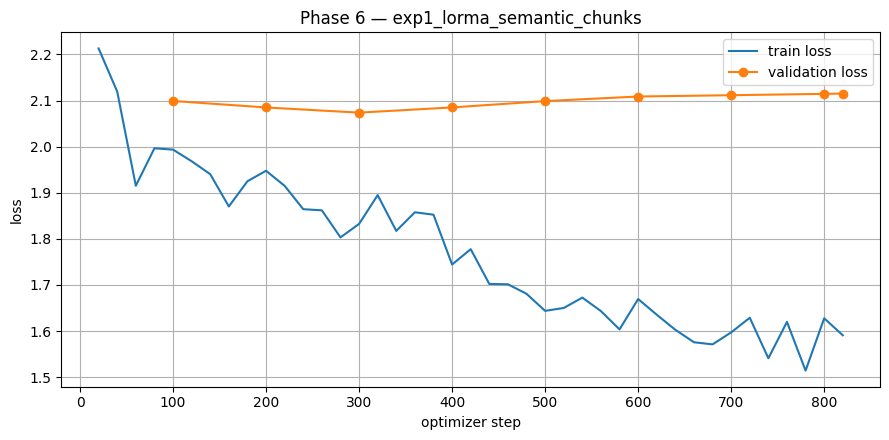

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4.5))
plt.plot(history["train_steps"], history["train_loss"], label="train loss")
plt.plot(history["val_steps"], history["val_loss"], marker="o", label="validation loss")
plt.xlabel("optimizer step")
plt.ylabel("loss")
plt.title(f"Phase 6 — {experiment_name}")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(run_dir, "loss_curve.png"), dpi=150)
plt.show()


In [26]:
@torch.no_grad()
def generate_texts(prompt_ids_list, max_new_tokens):
    model.eval()
    results = [""] * len(prompt_ids_list)
    order = sorted(range(len(prompt_ids_list)), key=lambda i: len(prompt_ids_list[i]))
    for b in range(0, len(order), gen_batch_size):
        idxs = order[b:b + gen_batch_size]
        batch = [prompt_ids_list[i] for i in idxs]
        L = max(len(p) for p in batch)
        input_ids = torch.full((len(batch), L), pad_id, dtype=torch.long)
        attn_mask = torch.zeros((len(batch), L), dtype=torch.long)
        for r, p in enumerate(batch):
            input_ids[r, L - len(p):] = torch.tensor(p, dtype=torch.long)
            attn_mask[r, L - len(p):] = 1

        def summary_finished(best_beams):
            return [end_marker in tokenizer.decode(t, skip_special_tokens=True) for t in best_beams.tolist()]

        out = model.generate_beam(
            idx=input_ids.to(device), max_new_tokens=max_new_tokens, num_beams=num_beams, temperature=1.0,
            attention_mask=attn_mask.to(device), no_repeat_ngram_size=no_repeat_ngram,
            banned_token_ids=banned_token_ids, stop_check=summary_finished, check_every=16,
        )
        for r, i in enumerate(idxs):
            text = tokenizer.decode(out[r, L:].tolist(), skip_special_tokens=True)
            results[i] = text.split(end_marker)[0].strip()
    return results

def summarize_documents(records, desc="documents"):
    chunks_per_doc = []
    for rec in records:
        sentences = split_sentences(rec["document"])
        _, chunks = process_document(sentences) if sentences else (None, [])
        chunks_per_doc.append(chunks)

    flat_prompts = [build_ids(c["text"], stage1_marker_ids, stage1_context_cap) for chunks in chunks_per_doc for c in chunks]
    print(f"[{desc}] {len(records)} docs -> {len(flat_prompts)} chunks to summarise (stage 1)...", flush=True)
    t0 = time.time()
    flat_summaries = generate_texts(flat_prompts, max_new_tokens=stage1_target_max_tokens + len(end_ids))
    print(f"[{desc}] stage 1 done in {(time.time() - t0) / 60:.1f} min", flush=True)

    chunk_summaries_per_doc, pos = [], 0
    for chunks in chunks_per_doc:
        chunk_summaries_per_doc.append(flat_summaries[pos:pos + len(chunks)])
        pos += len(chunks)

    joined_per_doc = [join_chunk_summaries(cs, stage2_input_max_tokens) for cs in chunk_summaries_per_doc]
    stage2_prompts = [build_ids(j, stage2_marker_ids, stage2_context_cap) for j in joined_per_doc]
    t0 = time.time()
    finals = generate_texts(stage2_prompts, max_new_tokens=stage2_target_max_tokens + len(end_ids))
    print(f"[{desc}] stage 2 done in {(time.time() - t0) / 60:.1f} min", flush=True)

    outputs = []
    for rec, final, joined, cs in zip(records, finals, joined_per_doc, chunk_summaries_per_doc):
        if not final.strip():
            final = joined or " ".join(rec["document"].split()[:150])
        outputs.append({"id": rec["id"], "summary": final, "chunk_summaries": cs})
    return outputs


In [27]:
from rouge_score import rouge_scorer

def rouge_report(predictions, references):
    scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)
    per_metric = {"rouge1": [], "rouge2": [], "rougeL": []}
    for pred, ref in zip(predictions, references):
        s = scorer.score(ref, pred)
        for k in per_metric:
            per_metric[k].append(s[k].fmeasure)
    return {k: float(np.mean(v)) for k, v in per_metric.items()}

val_eval_records = val_records[:num_val_docs_to_eval]
val_outputs = summarize_documents(val_eval_records, desc="validation")
val_preds = [o["summary"] for o in val_outputs]
val_refs = [r["summary"] for r in val_eval_records]

print("ROUGE F1:", {k: round(v, 4) for k, v in rouge_report(val_preds, val_refs).items()})
if compute_bertscore:
    from bert_score import score as bert_score
    _, _, F1 = bert_score(val_preds, val_refs, lang="en", verbose=False)
    print(f"BERTScore F1: {F1.mean().item():.4f}")

print(f"\nAvg predicted length: {np.mean([len(p.split()) for p in val_preds]):.0f} words | "
      f"avg reference length: {np.mean([len(r.split()) for r in val_refs]):.0f} words")
print("\n──── Example (validation doc 0) ────")
print("CHUNK SUMMARIES:")
for k, s in enumerate(val_outputs[0]["chunk_summaries"][:3]):
    print(f"  [{k}] {s[:300]}")
print("\nFINAL SUMMARY :", val_outputs[0]["summary"][:1200])
print("\nREFERENCE     :", val_refs[0][:1200])

with open(os.path.join(run_dir, "val_outputs.json"), "w", encoding="utf-8") as f:
    json.dump(val_outputs, f, ensure_ascii=False, indent=2)


[validation] 10 docs -> 185 chunks to summarise (stage 1)...
[validation] stage 1 done in 2.0 min
[validation] stage 2 done in 0.4 min
ROUGE F1: {'rouge1': 0.3858, 'rouge2': 0.1881, 'rougeL': 0.2174}

Avg predicted length: 246 words | avg reference length: 800 words

──── Example (validation doc 0) ────
CHUNK SUMMARIES:
  [0] The respondent filed a suit against the appellant for recovery of a sum of Rs.3,45,000 on the ground that the appellant was liable to discharge the mortgage and against that order of the High Court the appellant preferred civil appeal No. 111(N) of 1981.
  [1] The appellant deposited a sum of Rs.2,42.822.19 on 29 May, 1980 in the High Court with the undertaking to give up all her rights under the mortgage decree passed in her favour in C.S. No. 154 of 1968 except to the extent of the amount actually paid to the South Indian Bank for taking the assignment.
  [2] The High Court found that the appellant was bound to comply with the Original Side Rules of the High Cou

In [28]:
test_outputs = summarize_documents(test_records, desc="test")

predictions = [{"id": o["id"], "summary": o["summary"]} for o in test_outputs]
with open(prediction_path, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)
with open(os.path.join(run_dir, "test_chunk_summaries.json"), "w", encoding="utf-8") as f:
    json.dump(test_outputs, f, ensure_ascii=False, indent=2)

assert len(predictions) == len(test_records)
assert {p["id"] for p in predictions} == {r["id"] for r in test_records}, "ID mismatch with test file!"
assert all(p["summary"].strip() for p in predictions), "Empty summary found"

with zipfile.ZipFile(submission_zip, "w", compression=zipfile.ZIP_DEFLATED) as z:
    z.write(prediction_path, arcname="prediction.json")
print("Submission ready:", submission_zip)
print(f"Average summary length: {np.mean([len(p['summary'].split()) for p in predictions]):.0f} words")


[test] 100 docs -> 1486 chunks to summarise (stage 1)...
[test] stage 1 done in 15.6 min
[test] stage 2 done in 2.4 min
Submission ready: /kaggle/working/cs781_phase6/exp1_lorma_semantic_chunks/submission.zip
Average summary length: 221 words
